# TP 2 : Méthode factorielle - Analyse en Composantes Principales (A.C.P)

## Présentation de l'étude 

Les alcools de structures différentes sont fréquemment utilisés dans les produits d'hygiène et les cosmétiques. Il est souhaitable de classer ces alcools afin d'évaluer leurs effets nocifs potentiels à l'aide de méthodes moins coûteuses.
5 gaz sont particulièrement intéressants d'identifier : 

- 1-octanol, connu sous le nom d'alcool gras, avec son odeur forte, généralement utilisé dans les parfums et arômes;
- 1-propanol, ressemble beaucoup à l'alcool éthylique chimiquement avec une odeur forte et toxique, plutôt utilisé comme solvant;
- 2-butanol, alcool secondaire, est un solvant puissant;
- 2-propanol, alcool secondaire utilisé à la maison et dans l'industrie;
- 1-isobutanol, utilisé comme solvant.  

Le capteur QCM  (microbalance de cristal de quartz) est un dispositif physique qui est sensible aux changements de fréquence de résonance. Le but de l'étude est de mesurer l'action de différents capteurs QCM sur ces 5 alcools différents, et de déterminer quel type de capteur est le plus efficace dans la classification de ces alcools.

## Présentation des capteurs utilisés et des données générées

Pour cela, cinq capteurs QCM de gaz différents (QCM3, QCM6, QCM7, QCM10, QCM12) sont utilisés et cinq mesures de gaz différentes (1-octanol , 1-propanol, 2-butanol, 2-propanol et 1-isobutanol) sont effectuées pour chacun de ces capteurs.

L'échantillon de gaz passe à travers le capteur en cinq concentrations différentes. Ces concentrations sont :
  
    Rapport d'air (ml)   Rapport de gaz (ml) 
    0.799                0.201 
    0.700                0.300 
    0.600                0.400 
    0.501                0.499 
    0.400                0.600 

Les rapports  sur les polymères à empreintes moléculaires (MIP) et les nanoparticules (NP) utilisés dans les capteurs QCM sont :

    Capteur	 Ratio MIP   Ratio NP
      QCM3	      1	        1 
      QCM6          1	        0 
      QCM7	      1	        0.5 
      QCM10	     1            2 
      QCM12	     0	        1
      

## Références 

**Dataset :** https://archive.ics.uci.edu/ml/datasets/Alcohol+QCM+Sensor+Dataset

**Article :** M. Fatih Adak, Peter Lieberzeit, Purim Jarujamrus, Nejat Yumusak, *Classification of alcohols obtained by QCM sensors with different characteristics using ABC based neural network*, Engineering Science and Technology, an International Journal, 2019.
https://www.sciencedirect.com/science/article/pii/S2215098619303337?via%3Dihub

In [1]:
import numpy as np
from io import StringIO
import matplotlib.pyplot as plt

In [2]:
# Afficher l'entête du jeu de données du capteur QCM3
fichier=open('QCM3.csv', "r")
print(fichier.readline())

# Charger l'ensemble de données et stocker dans la matrice Data
Data = np.genfromtxt('QCM3.csv',delimiter=";",skip_header=1,usecols = (range(0,10)))

# Afficher le jeu de données
print(Data)
print(Data.shape[1])

# Afficher les dimensions de la matrice des données
print("Dimensions de la matrice de donnees", Data.shape)

# 

"0.799_0.201";"0.799_0.201";"0.700_0.300";"0.700_0.300";"0.600_0.400";"0.600_0.400";"0.501_0.499";"0.501_0.499";"0.400_0.600";"0.400_0.600";"1-Octanol";"1-Propanol";"2-Butanol";"2-propanol";"1-isobutanol"

[[ -10.06  -10.62  -14.43  -18.31  -24.64  -30.56  -38.62  -45.59  -54.89
   -62.28]
 [  -9.69  -10.86  -16.73  -21.75  -28.47  -35.83  -43.65  -52.43  -61.92
   -71.27]
 [ -12.07  -14.28  -21.54  -27.92  -35.19  -43.94  -52.04  -62.49  -71.97
   -83.1 ]
 [ -14.21  -17.41  -25.91  -33.36  -41.29  -51.27  -59.94  -71.55  -81.51
   -93.83]
 [ -16.57  -20.35  -29.97  -37.84  -47.03  -57.29  -67.13  -78.96  -90.01
  -102.65]
 [ -75.61  -64.1  -122.08 -102.17 -174.79 -145.5  -214.69 -177.3  -250.83
  -207.99]
 [ -76.28  -64.53 -123.4  -103.06 -174.74 -144.98 -206.75 -170.68 -240.14
  -200.05]
 [ -76.96  -65.37 -124.5  -103.87 -169.93 -140.56 -200.89 -165.88 -232.82
  -194.7 ]
 [ -78.29  -66.49 -125.78 -104.77 -165.42 -136.17 -196.1  -161.99 -226.89
  -189.57]
 [ -79.62  -66.85 -126.61 -10

# Partie I : Analyse en composantes principales (ACP)

L'ACP consiste à transformer des variables liées entre elles (dites « corrélées » en statistique) en nouvelles variables décorrélées les unes des autres. Ces nouvelles variables sont nommées « composantes principales », ou axes principaux. Elle permet au praticien de réduire le nombre de variables et de rendre l'information moins redondante.


Il s'agit d'une approche à la fois géométrique (les variables étant représentées dans un nouvel espace, selon des directions d'inertie maximale) et statistique (la recherche portant sur des axes indépendants expliquant au mieux la variabilité — la variance — des données). Lorsqu'on veut compresser un ensemble de N variables aléatoires, les 
n premiers axes de l'analyse en composantes principales sont un meilleur choix, du point de vue de l'inertie ou de la variance.

<img src="./PCAexple.png" width="500" height="500"  >


**Principe :** 

Les composantes principales $C_1,..,C_q$ sont des nouvelles variables combinaison linéaire des variables d'origines $x_{.1},...x_{.p}$ telles que :
-  les $C_k$ soient 2 à 2 non corrélées, 
- de variance maximale, 
- d'importance décroissante.

**Définition d'axe principal:**
On appelle le *premier (resp. second...) axe principal* le vecteur propre associé à la plus grande (resp. à la seconde plus grande...) valeur propre de la matrice de variance-covariance des données.



(10, 10)
(10, 2)
(25, 2)


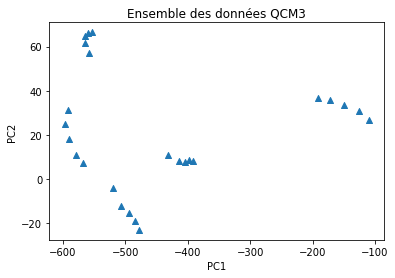

In [3]:
# Matrice de variance-covariance sur les données QCM3
n_components=2 # nombre de dimensions réduites
cov_mat=np.cov(np.transpose(Data)) # calcul de la matrice de var-cov

# Dimension de la matrice de variance-covariance
print(cov_mat.shape)

# Extraction des valeurs propres et vecteurs propres
eig_vals, eig_vecs = np.linalg.eig(cov_mat)

# Définition des axes principaux
principalAxes=np.zeros((Data.shape[1],n_components))
for i in range(n_components):
    principalAxes[:,i]=eig_vecs[:,i]

# Dimension des axes principaux
print(principalAxes.shape)


# Calcul des composantes principales c'est-à-dire les coefficients de projection des données 
# dans le nouveau repère défini par les axes principaux
principalComponents = Data.dot(principalAxes)

# Dimension des composantes principales
print(principalComponents.shape)



# aAffichage des points
plt.scatter(principalComponents[:, 0], principalComponents[:, 1],marker='^')
plt.title("Ensemble des données QCM3")
plt.xlabel("PC1")
plt.ylabel("PC2");
plt.show()



(10, 10)
(10, 2)


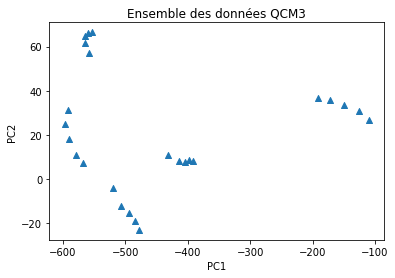

In [4]:
# Matrice de variance-covariance sur les données QCM3
n_components=2 # nombre de dimensions réduites
cov_mat=np.cov(np.transpose(Data)) # calcul de la matrice de var-cov

# Dimension de la matrice de variance-covariance
print(cov_mat.shape)

# Extraction des valeurs propres et vecteurs propres
eig_vals, eig_vecs = np.linalg.eig(cov_mat)

# Définition des axes principaux
principalAxes=np.zeros((Data.shape[1],n_components))
for i in range(n_components):
    principalAxes[:,i]=eig_vecs[:,i]

# Dimension des axes principaux
print(principalAxes.shape)


# Calcul des composantes principales c'est-à-dire les coefficients de projection des données 
# dans le nouveau repère défini par les axes principaux
principalComponents = Data.dot(principalAxes)

# aAffichage des points
fig = plt.figure()
plt.scatter(principalComponents[:, 0], principalComponents[:, 1],marker='^')
plt.title("Ensemble des données QCM3")
plt.xlabel("PC1")
plt.ylabel("PC2");
plt.show()




# Pourcentage d'information conservée


La qualité des estimations auxquelles conduit l'A.C.P. dépend, de façon évidente, du choix de $q$ c'est-à-dire du nombre de composantes retenues pour reconstituer les données, ou encore de la dimension du sous-espace de représentations.

La "qualité globale" des représentations est mesurée par la part d'inertie expliquée : 

$$r_q=\frac{\sum_{k=1}^q \lambda_k}{\sum_{i=1}^p \lambda_i}.$$


In [5]:
Contraste=sum(eig_vals[range(n_components)])/sum(eig_vals)
print("Contraste :", Contraste)

Contraste : 0.9858687136440786


# Partie II : Utilisation de la librairie Scikit-learn (https://scikit-learn.org/)



Analyse en Composantes Principales : 
https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

In [6]:
import sklearn 
from sklearn.decomposition import PCA

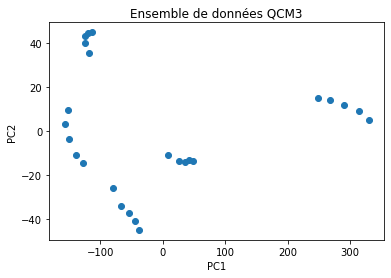

0.9858687136440782


In [7]:
n_components=2
pca = PCA(n_components)
principalComponents = pca.fit_transform(Data)


# affichage des points
plt.scatter(principalComponents[:, 0], principalComponents[:, 1],marker='o')
plt.title("Ensemble de données QCM3")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()



# Conservation de l'information : Variance 
print(sum(pca.explained_variance_ratio_))



# Partie III : Travail demandé 

- Réaliser une Analyse en Composantes Principales sur les autres capteurs QCM